In [1]:
import os, sys

# Make the notebook runnable both interactively (from the repo root) and via
# `jupyter nbconvert --execute` (kernel cwd = experiments/).
if not os.path.isdir(os.path.join(os.getcwd(), 'tskan')):
    _root = os.path.abspath(os.path.join(os.getcwd(), '..'))
    os.chdir(_root)
    sys.path.insert(0, _root)


# TSKAN on Waterloo QoE Database 3

Same two-stage TSKAN procedure as in `01_tskan_netflix.ipynb`, applied to the
Waterloo QoE Database 3 (5 chunks x 6 variables; the 7th variable, video height,
is dropped).

- DFT features, F=1: per variable |X(0)|, |X(1)|, angle(X(0)), angle(X(1))
  -> 6 x 4 = 24 features (the DC phase is retained here, as in the paper)
- Scaling: `RobustScaler(quantile_range=(20.0, 80.0))`, fitted on train only
- Stage 1: KAN `width=[24, 1]`, `grid=3`, `k=3`, `seed=5`, LBFGS, `lr=0.001`, 20 steps
- Stage 2: top-10 features, KAN `width=[10, 1]`, `grid=3`, `k=3`, `seed=5`, 20 steps

Run from the repository root: `python -m jupyter notebook experiments/02_tskan_waterloo3.ipynb`


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import mean_squared_error

from tskan.data import load_dataset
from tskan.features import dft_features, dft_feature_names
from tskan.model import TSKAN


In [3]:
# Processed splits: data/waterloo3/waterloo3_zscore_{TRAIN,VALID,TEST}.ts
data = load_dataset('waterloo3', data_dir='data')
print('train', data['X_train'].shape, '| valid', data['X_valid'].shape, '| test', data['X_test'].shape)


train (326, 7, 5) | valid (65, 7, 5) | test (59, 7, 5)


In [4]:
# Drop the 7th variable (video height)
X_train = data['X_train'][:, :6, :]
X_valid = data['X_valid'][:, :6, :]
X_test  = data['X_test'][:, :6, :]
y_train, y_valid, y_test = data['y_train'], data['y_valid'], data['y_test']


In [5]:
# DFT features, F=1, including the DC phase: 6 x 4 = 24 features
X_train_f = dft_features(X_train, F=1, include_dc_phase=True)
X_valid_f = dft_features(X_valid, F=1, include_dc_phase=True)
X_test_f  = dft_features(X_test,  F=1, include_dc_phase=True)
print('features:', X_train_f.shape[1])
feat_names = dft_feature_names(V=6, F=1, include_dc_phase=True)


features: 24


In [6]:
# Clean non-finite values and scale (fitted on train only)
X_train_f = np.nan_to_num(X_train_f, nan=0.0, posinf=0.0, neginf=0.0)
X_valid_f = np.nan_to_num(X_valid_f, nan=0.0, posinf=0.0, neginf=0.0)
X_test_f  = np.nan_to_num(X_test_f,  nan=0.0, posinf=0.0, neginf=0.0)

scaler = RobustScaler(quantile_range=(20.0, 80.0))
X_train_sc = scaler.fit_transform(X_train_f)
X_valid_sc = scaler.transform(X_valid_f)
X_test_sc  = scaler.transform(X_test_f)


In [7]:
# Stage 1: 1-layer KAN on all 24 DFT features
model = TSKAN(24, grid=3, k=3, seed=5, device='cpu')
model.fit(X_train_sc, y_train, X_valid_sc, y_valid, steps=20, lr=0.001)


description:   0%|                                                           | 0/20 [00:00<?, ?it/s]

| train_loss: 7.03e-01 | test_loss: 7.15e-01 | reg: 0.00e+00 | :   0%|       | 0/20 [00:00<?, ?it/s]

| train_loss: 7.03e-01 | test_loss: 7.15e-01 | reg: 0.00e+00 | :   5%| | 1/20 [00:00<00:12,  1.48it/

| train_loss: 5.50e-01 | test_loss: 6.18e-01 | reg: 0.00e+00 | :   5%| | 1/20 [00:00<00:12,  1.48it/

| train_loss: 4.87e-01 | test_loss: 5.28e-01 | reg: 0.00e+00 | :   5%| | 1/20 [00:00<00:12,  1.48it/

| train_loss: 4.87e-01 | test_loss: 5.28e-01 | reg: 0.00e+00 | :  15%|▏| 3/20 [00:00<00:03,  4.55it/

... (22 outputs left out)

| train_loss: 4.13e-01 | test_loss: 4.88e-01 | reg: 0.00e+00 | :  85%|▊| 17/20 [00:01<00:00, 15.10it

| train_loss: 4.13e-01 | test_loss: 4.88e-01 | reg: 0.00e+00 | :  95%|▉| 19/20 [00:01<00:00, 15.71it

| train_loss: 4.13e-01 | test_loss: 4.84e-01 | reg: 9.70e+00 | :  95%|▉| 19/20 [00:01<00:00, 15.71it

| train_loss: 4.13e-01 | test_loss: 4.84e-01 | reg: 9.70e+00 | : 100%|█| 20/20 [00:01<00:00, 10.79it

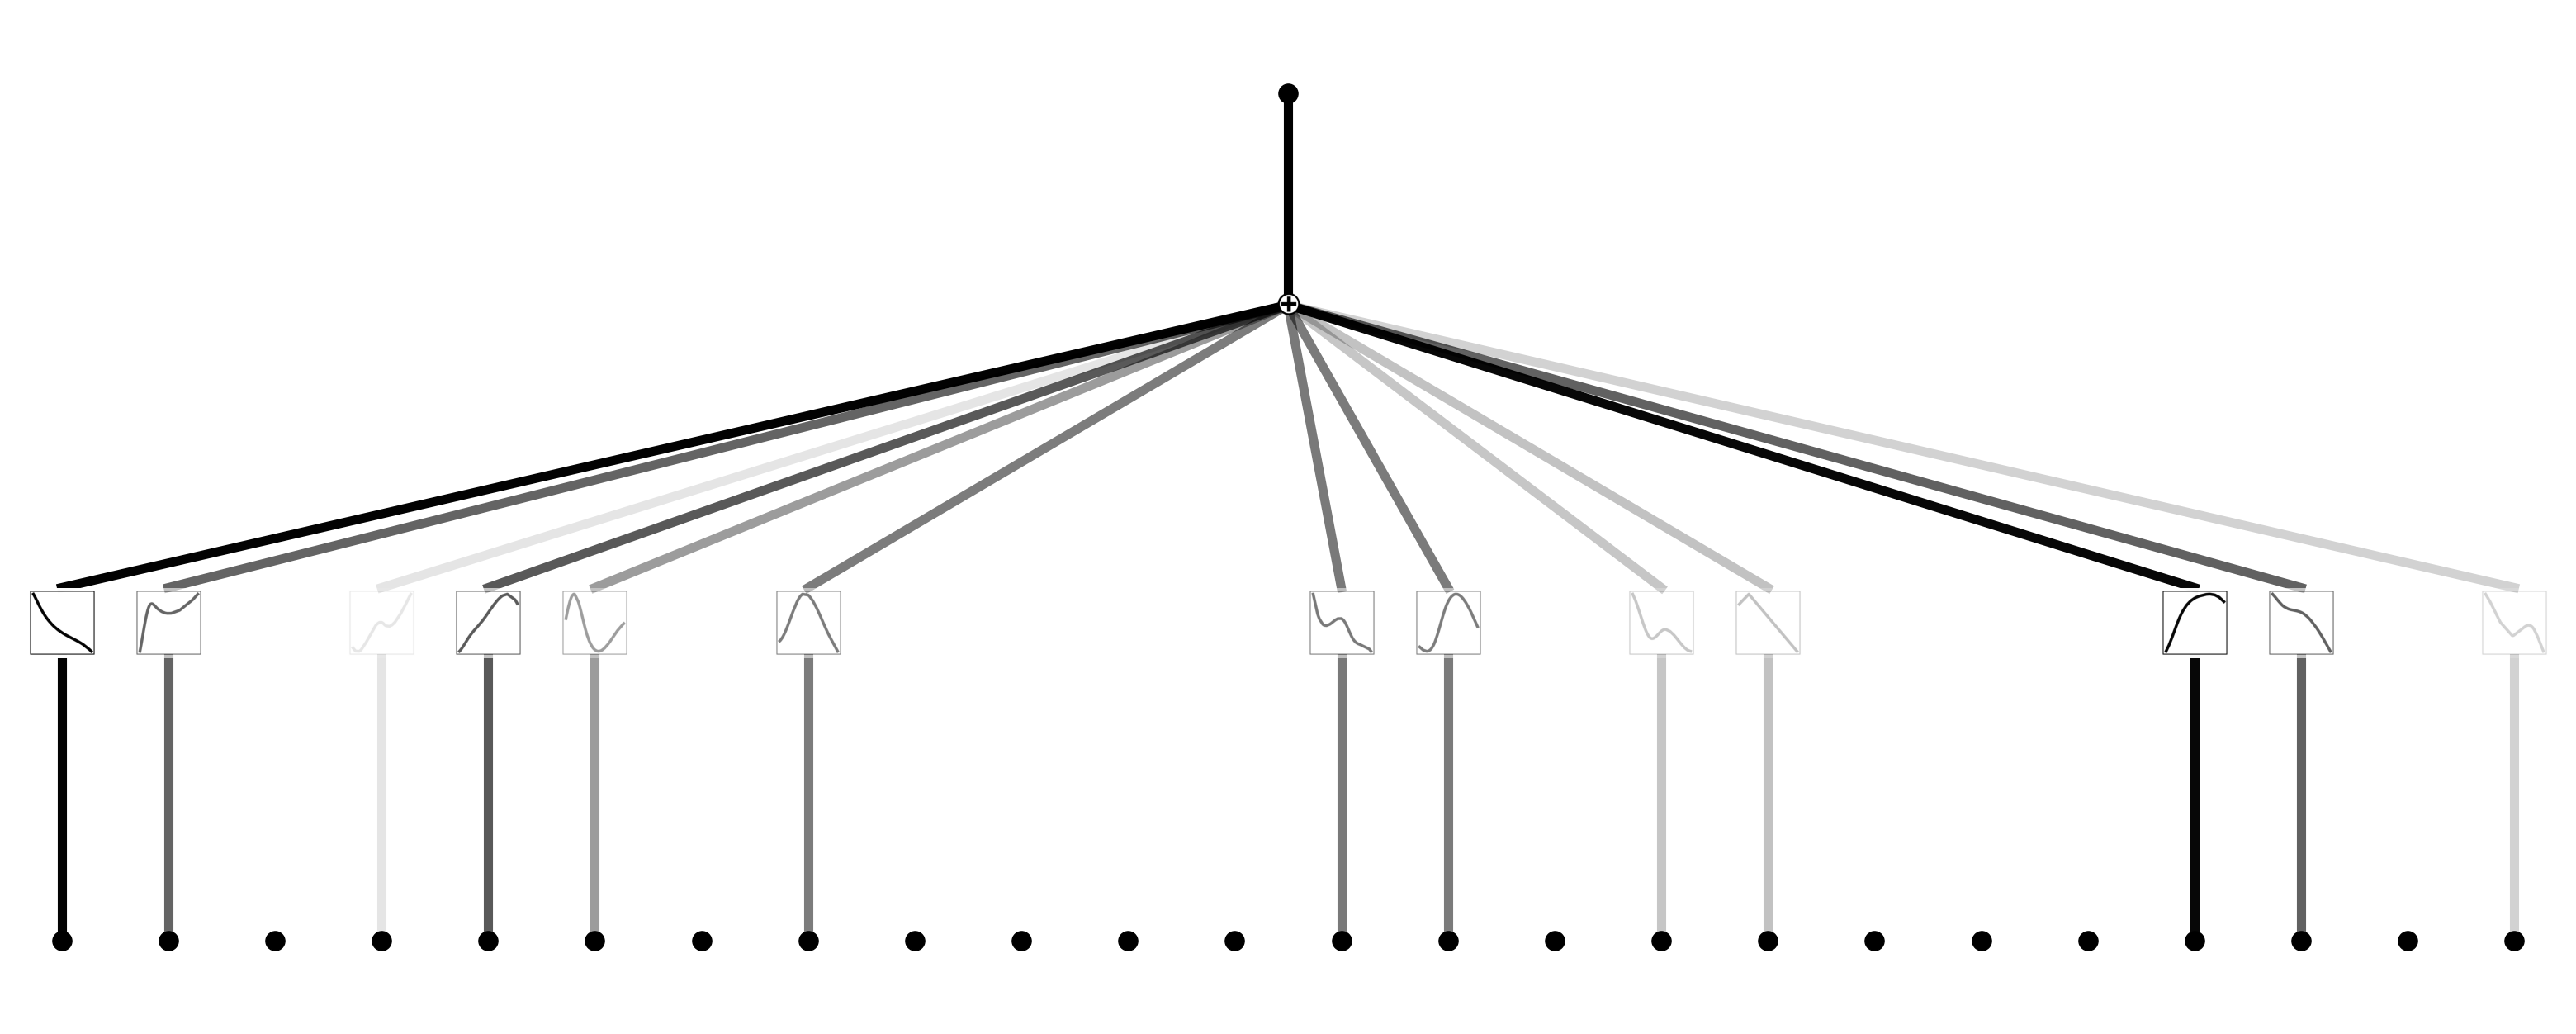

In [8]:
model.plot(scale=4)


In [9]:
model.importance


tensor([0.9166, 0.2346, 0.0000, 0.0335, 0.2585, 0.1360, 0.0000, 0.1900, 0.0000,
        0.0000, 0.0000, 0.0000, 0.1949, 0.1908, 0.0000, 0.0757, 0.0818, 0.0000,
        0.0000, 0.0000, 0.7238, 0.2424, 0.0000, 0.0595])

Text(0.5, 1.0, 'Stage 1 (24 features)')

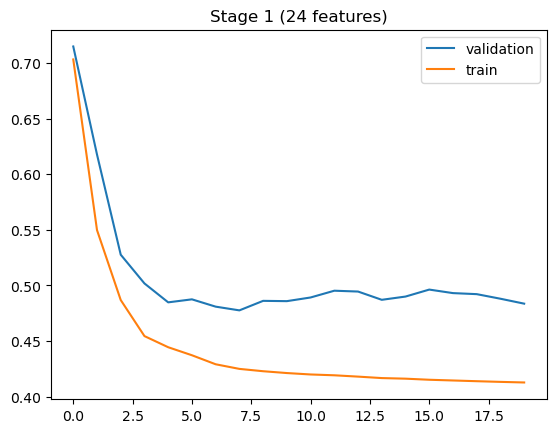

In [10]:
plt.plot(model.train_history['test_loss'], label='validation')
plt.plot(model.train_history['train_loss'], label='train')
plt.legend(); plt.title('Stage 1 (24 features)')


In [11]:
topk = model.top_k_indices(k=10)
topk


array([ 0,  1,  4,  5,  7, 12, 13, 16, 20, 21])

In [12]:
[feat_names[i] for i in topk]


['M_rebuffering_duration(0)',
 'M_rebuffering_duration(1)',
 'M_video_bitrate(0)',
 'M_video_bitrate(1)',
 'phase_video_bitrate(1)',
 'M_qp(0)',
 'M_qp(1)',
 'M_framerate(0)',
 'M_width(0)',
 'M_width(1)']

In [13]:
# Stage 2: 1-layer KAN on the top-10 features only
model = TSKAN(10, grid=3, k=3, seed=5, device='cpu')
model.fit(X_train_sc[:, topk], y_train, X_valid_sc[:, topk], y_valid, steps=20, lr=0.001)


description:   0%|                                                           | 0/20 [00:00<?, ?it/s]

| train_loss: 5.84e-01 | test_loss: 6.63e-01 | reg: 0.00e+00 | :   0%|       | 0/20 [00:00<?, ?it/s]

| train_loss: 4.72e-01 | test_loss: 5.12e-01 | reg: 0.00e+00 | :   0%|       | 0/20 [00:00<?, ?it/s]

| train_loss: 4.72e-01 | test_loss: 5.12e-01 | reg: 0.00e+00 | :  10%| | 2/20 [00:00<00:01, 17.06it/

| train_loss: 4.46e-01 | test_loss: 4.92e-01 | reg: 0.00e+00 | :  10%| | 2/20 [00:00<00:01, 17.06it/

| train_loss: 4.38e-01 | test_loss: 4.96e-01 | reg: 0.00e+00 | :  10%| | 2/20 [00:00<00:01, 17.06it/

... (22 outputs left out)

| train_loss: 4.19e-01 | test_loss: 4.83e-01 | reg: 0.00e+00 | :  90%|▉| 18/20 [00:01<00:00, 17.94it

| train_loss: 4.19e-01 | test_loss: 4.80e-01 | reg: 9.58e+00 | :  90%|▉| 18/20 [00:01<00:00, 17.94it

| train_loss: 4.19e-01 | test_loss: 4.80e-01 | reg: 9.58e+00 | : 100%|█| 20/20 [00:01<00:00, 16.82it

| train_loss: 4.19e-01 | test_loss: 4.80e-01 | reg: 9.58e+00 | : 100%|█| 20/20 [00:01<00:00, 17.31it

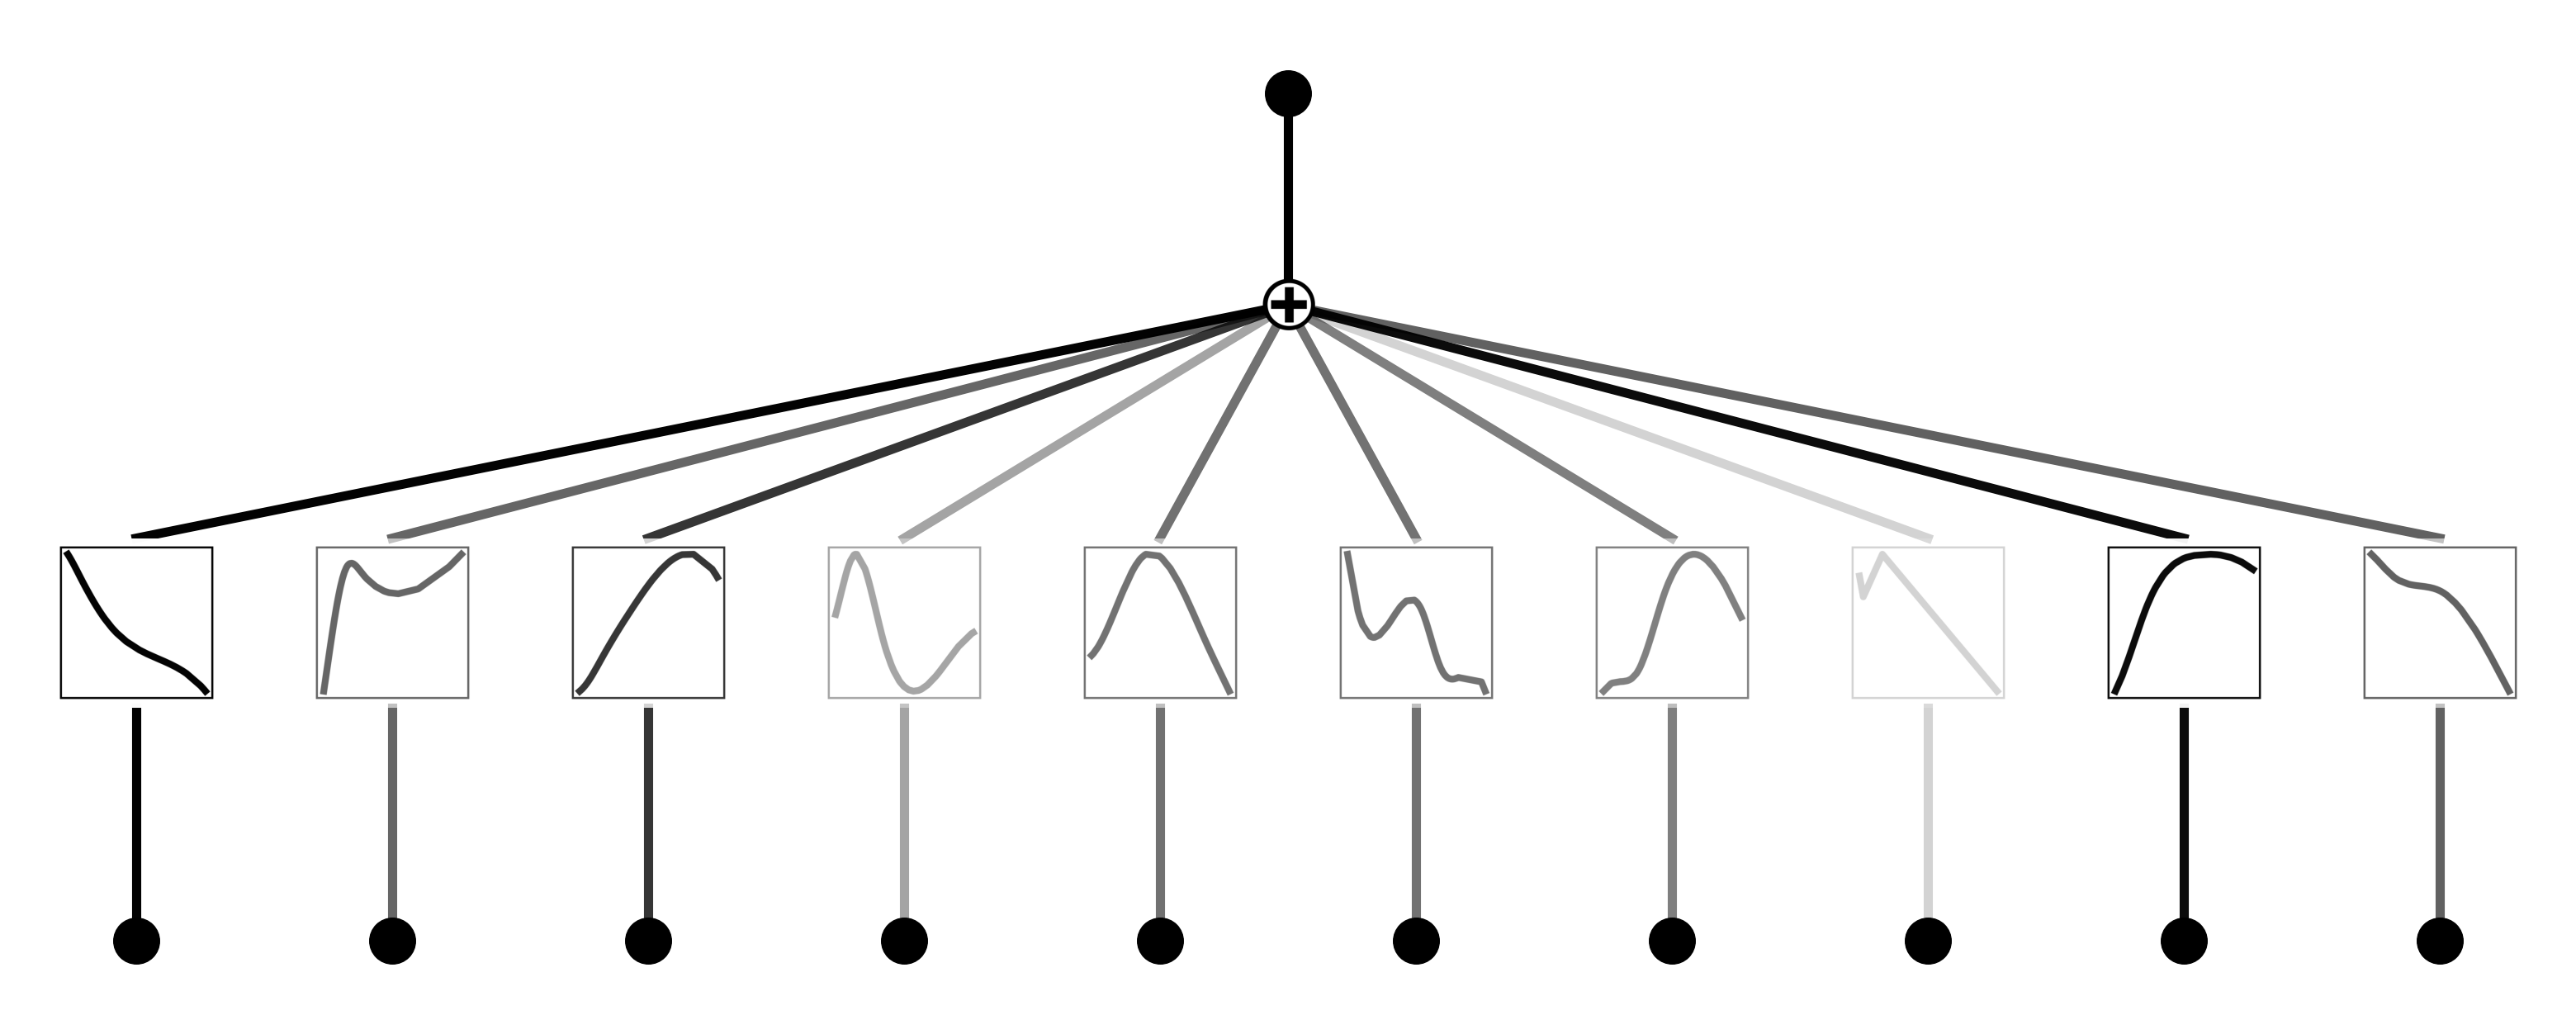

In [14]:
model.plot(scale=4)


Text(0.5, 1.0, 'Stage 2 (top-10 features)')

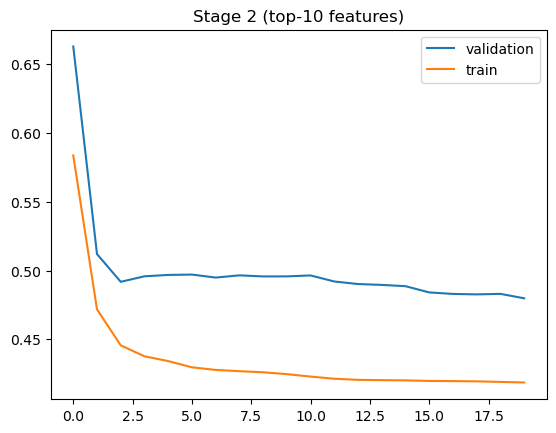

In [15]:
plt.plot(model.train_history['test_loss'], label='validation')
plt.plot(model.train_history['train_loss'], label='train')
plt.legend(); plt.title('Stage 2 (top-10 features)')


TSKAN test RMSE (Waterloo QoE DB 3): 0.4784353948683723


Text(0, 0.5, 'predicted')

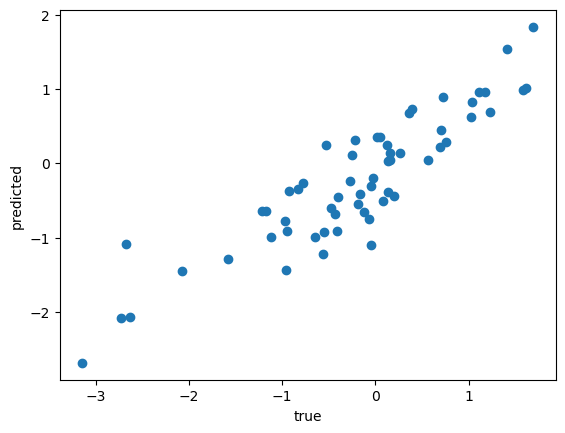

In [16]:
# Test set evaluation
y_pred = model.predict(X_test_sc[:, topk])
rmse = float(np.sqrt(mean_squared_error(y_test, y_pred)))
print('TSKAN test RMSE (Waterloo QoE DB 3):', rmse)
plt.scatter(y_test, y_pred)
plt.xlabel('true'); plt.ylabel('predicted')


In [17]:
print('number of trainable parameters:', model.n_params())


number of trainable parameters: 120


**Expected results** (paper, Tables I-II): TSKAN test RMSE = **0.4716** on
Waterloo QoE Database 3 with **120** trainable parameters.
